# Traffic Sign Recognition for Autonomous Vehicles

### ARTI 502 — Deep Learning Project

**Model 1: Custom Convolutional Neural Network (CNN)**

**Dataset:** German Traffic Sign Recognition Benchmark (GTSRB)

**Framework:** TensorFlow / Keras

**Objective:** To develop and train a custom CNN model for classifying traffic signs into 43 categories and provide baseline results for comparison with the YOLO model.


## Dataset Setup and Preparation

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

base = "/content/drive/MyDrive/ARTI502_Project"

print("Project folder exists:", os.path.exists(base))

if os.path.exists(base):
    print("Files inside:", os.listdir(base))


Project folder exists: True
Files inside: ['data', 'results', 'models', 'figures', 'notebooks', 'ARTI502_Final_Report.gdoc']


In [5]:
import os

DATA_DIR = os.path.join(base, "data")

print("Files in data folder:")
print(os.listdir(DATA_DIR))

for filename in [
    "train_split.csv",
    "val_split.csv",
    "test_split.csv"
]:
    path = os.path.join(DATA_DIR, filename)
    print(filename, "exists:", os.path.isfile(path))


Files in data folder:
['train_split.csv', 'val_split.csv', 'test_split.csv']
train_split.csv exists: True
val_split.csv exists: True
test_split.csv exists: True


In [6]:
import pandas as pd

train_df = pd.read_csv(os.path.join(DATA_DIR, "train_split.csv"))
val_df = pd.read_csv(os.path.join(DATA_DIR, "val_split.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test_split.csv"))

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nColumn names:", train_df.columns.tolist())

print("\nFirst 5 training rows:")
display(train_df.head())
print("\nMissing values:")
print(train_df.isnull().sum())


Training images: 31350
Validation images: 7859
Testing images: 12630

Column names: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'ClassName', 'TrackGroup']

First 5 training rows:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,ClassName,TrackGroup
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png,Dangerous curve right,00020_00000
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png,Dangerous curve right,00020_00000
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png,Dangerous curve right,00020_00000
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png,Dangerous curve right,00020_00000
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png,Dangerous curve right,00020_00000



Missing values:
Width         0
Height        0
Roi.X1        0
Roi.Y1        0
Roi.X2        0
Roi.Y2        0
ClassId       0
Path          0
ClassName     0
TrackGroup    0
dtype: int64


In [7]:
!pip -q install kagglehub

import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

print("Dataset downloaded to:", dataset_path)
print("Files:", os.listdir(dataset_path))


Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Dataset downloaded to: /kaggle/input/gtsrb-german-traffic-sign
Files: ['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']


Image path: /kaggle/input/gtsrb-german-traffic-sign/Train/20/00020_00000_00000.png
Image exists: True
Image size: (27, 26)
Class ID: 20
Class name: Dangerous curve right


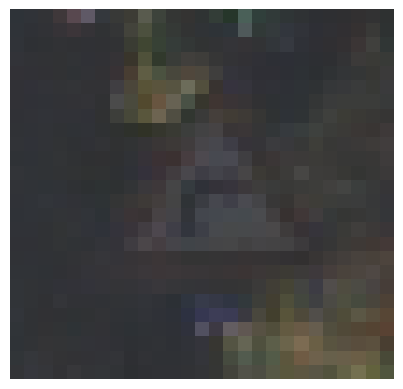

In [8]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATASET_ROOT = Path(dataset_path)
image_path = DATASET_ROOT / train_df.iloc[0]["Path"]
print("Image path:", image_path)
print("Image exists:", image_path.is_file())

if image_path.is_file():
    image = Image.open(image_path).convert("RGB")

    print("Image size:", image.size)
    print("Class ID:", train_df.iloc[0]["ClassId"])
    print("Class name:", train_df.iloc[0]["ClassName"])

    plt.imshow(image)
    plt.axis("off")
    plt.show()
else:
    print("Image not found. We need to check the dataset path.")


In [9]:
import tensorflow as tf
import numpy as np

IMG_SIZE = (32, 32)
BATCH_SIZE = 32
NUM_CLASSES = 43
SEED = 42

tf.keras.utils.set_random_seed(SEED)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_png(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(df, training=False):
    paths = [
        str(DATASET_ROOT / p)
        for p in df["Path"]
    ]
    labels = df["ClassId"].astype("int32").values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:",
          float(tf.reduce_min(images)),
          float(tf.reduce_max(images)))

Image batch shape: (32, 32, 32, 3)
Label batch shape: (32,)
Pixel range: 0.0 1.0


## Building a Custom CNN Model



In [10]:
from tensorflow.keras import layers, models

NAME = "model1"
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(43, activation="softmax")
], name="Custom_CNN")

model.summary()


Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,067 (1.38 MB)

 Trainable params: 361,067 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

## Compiling the CNN Model

In [11]:
from tensorflow.keras.optimizers import Adam

LEARNING_RATE = 0.001

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN compiled successfully!")
print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)
print("Loss: Sparse Categorical Crossentropy")
print("Metric: Accuracy")


CNN compiled successfully!
Optimizer: Adam
Learning rate: 0.001
Loss: Sparse Categorical Crossentropy
Metric: Accuracy


## Training the CNN Model

In [12]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import os

NAME = "model1"
MODEL_DIR = os.path.join(base, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    MODEL_DIR, f"{NAME}_best.keras"
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min"
    )
]
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks,
    verbose=1
)
print("Training completed!")
print("Best model saved to:", checkpoint_path)


Epoch 1/25
313/980 ━━━━━━━━━━━━━━━━━━━━ 1:52 168ms/step - accuracy: 0.1058 - loss: 3.3946

KeyboardInterrupt: 

## Model Evaluation and Visualization

In [ ]:
import matplotlib.pyplot as plt
import os

train_acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_acc) + 1)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_acc, label="Training Accuracy")
plt.plot(epochs_range, val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Custom CNN - Accuracy")
plt.legend()
plt.grid(True) #Accuracy Graph


plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom CNN - Loss")
plt.legend()
plt.grid(True) #Loss Graph

plt.tight_layout()
FIGURES_DIR = os.path.join(base, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

figure_path = os.path.join(
    FIGURES_DIR, "model1_training_curves.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graphs saved to:", figure_path)


## Testing and Evaluating the Best Custom CNN Model

In [ ]:
import os
import tensorflow as tf

best_model_path = os.path.join(
    base, "models", "model1_best.keras"
)

assert os.path.isfile(best_model_path), "Saved model not found!"
best_model = tf.keras.models.load_model(best_model_path)
print("Best Custom CNN model is loaded successfully!")

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\n CUSTOM CNN TEST RESULTS ")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

## Confusion Matrix and Classification Report

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = best_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(43),
    zero_division=0
)

print("Custon CNN Classification Report")
print(report)
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(43)
)

fig, ax = plt.subplots(figsize=(15, 13))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(43)
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=True,
    values_format="d"
)

plt.title("Custom CNN - Confusion Matrix")
plt.tight_layout()

cm_path = os.path.join(
    base, "figures", "model1_confusion_matrix.png"
)

plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", cm_path)

## Sample Predictions and Error Analysis

This section visualizes the predictions of the trained Custom CNN on unseen test images. Correct and incorrect predictions are displayed to analyze the model's classification performance.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

sample_images = []
sample_labels = []

for images, labels in test_ds:
    sample_images.append(images.numpy())
    sample_labels.append(labels.numpy())

X_test = np.concatenate(sample_images, axis=0)
y_true = np.concatenate(sample_labels, axis=0)

pred_probs = best_model.predict(X_test, batch_size=32, verbose=1)
y_pred = np.argmax(pred_probs, axis=1) #predict using the best saved Custom CNN

#identify correct and incorrect predictions
correct_indices = np.where(y_true == y_pred)[0]
incorrect_indices = np.where(y_true != y_pred)[0]
print("Correct predictions:", len(correct_indices))
print("Incorrect predictions:", len(incorrect_indices))


#select 5 correct and 5 incorrect examples
rng = np.random.default_rng(42)
selected_correct = rng.choice(
    correct_indices,
    size=min(5, len(correct_indices)),
    replace=False
)

selected_incorrect = rng.choice(
    incorrect_indices,
    size=min(5, len(incorrect_indices)),
    replace=False
)

selected_indices = np.concatenate([
    selected_correct,
    selected_incorrect
])

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for ax, idx in zip(axes.flat, selected_indices):
    ax.imshow(X_test[idx])
    ax.set_title(
        f"True: {y_true[idx]}\n"
        f"Predicted: {y_pred[idx]}\n"
        f"Confidence: {np.max(pred_probs[idx])*100:.1f}%",
        color="green" if y_true[idx] == y_pred[idx] else "red",
        fontsize=10
    )
    ax.axis("off")

for ax in axes.flat[len(selected_indices):]:
    ax.axis("off")

plt.suptitle("Custom CNN - Sample Test Predictions", fontsize=16)
plt.tight_layout()
save_path = os.path.join(
    base, "figures", "model1_sample_predictions.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Sample predictions saved to:", save_path)


In [ ]:
import numpy as np
import pandas as pd
import os
import tensorflow as tf

best_model = tf.keras.models.load_model(
    os.path.join(base, "models", "model1_best.keras")
)

probs = best_model.predict(test_ds, verbose=1)

y_true = test_df["ClassId"].to_numpy()
y_pred = probs.argmax(axis=1)

assert len(y_true) == len(y_pred), "Prediction count mismatch!"
pd.DataFrame({
    "y_true": y_true,
    "y_pred": y_pred
}).to_csv(
    os.path.join(base, "results", "model1_preds.csv"),
    index=False
)

np.save(
    os.path.join(base, "results", "model1_probs.npy"),
    probs
)

print("Files saved successfully!")
print("Test accuracy:", (y_pred == y_true).mean())


## Model Performance Summary

In [ ]:
import pandas as pd
import os

results = {
    "Model": ["Custom CNN"],
    "Dataset": ["GTSRB"],
    "Number of Classes": [43],
    "Test Images": [len(y_true)],
    "Test Accuracy": [round(test_accuracy, 4)],
    "Test Loss": [round(test_loss, 4)],
    "Correct Predictions": [int(np.sum(y_true == y_pred))],
    "Incorrect Predictions": [int(np.sum(y_true != y_pred))]
}

results_df = pd.DataFrame(results)
display(results_df)
results_path = os.path.join(
    base, "results", "model1_results.csv"
)

results_df.to_csv(results_path, index=False)

print("CNN results saved to:", results_path)


## Dataset Split Verification

In [ ]:
#just checking dataset split sizes and overlapping paths
train_paths = set(train_df["Path"].astype(str))
val_paths = set(val_df["Path"].astype(str))
test_paths = set(test_df["Path"].astype(str))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nOverlapping image paths:")
print("Train vs Validation:", len(train_paths & val_paths))
print("Train vs Test:", len(train_paths & test_paths))
print("Validation vs Test:", len(val_paths & test_paths))

print("\nDuplicate paths within splits:")
print("Train:", train_df["Path"].duplicated().sum())
print("Validation:", val_df["Path"].duplicated().sum())
print("Test:", test_df["Path"].duplicated().sum())


## Final Dataset Integrity Check

In [ ]:
#check whether the same traffic-sign track does appear in both training and validation

train_groups = set(train_df["TrackGroup"].astype(str))
val_groups = set(val_df["TrackGroup"].astype(str))
shared_groups = train_groups & val_groups

print("Training track groups:", len(train_groups))
print("Validation track groups:", len(val_groups))
print("Shared train/validation groups:", len(shared_groups))

if len(shared_groups) == 0:
    print("PASS: No TrackGroup overlap.")
else:
    print("WARNING: TrackGroup overlap detected.")
    print("Example shared groups:", sorted(shared_groups)[:10])


## Custom CNN – Model Loading and Preparation for YOLO Integration

This section loads the previously trained Custom CNN model, defines a function to classify cropped traffic sign images, and verifies its predictions using a sample from the GTSRB test dataset. This CNN will later be integrated with YOLO to classify detected traffic signs.

In [14]:
import os

model_path = "/content/drive/MyDrive/ARTI502_Project/models/model1_best.keras"

print("Model exists:", os.path.isfile(model_path))

Model exists: True


In [15]:
import tensorflow as tf

cnn = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("CNN ready!")
print("Input shape:", cnn.input_shape)
print("Output shape:", cnn.output_shape)

CNN ready!
Input shape: (None, 32, 32, 3)
Output shape: (None, 43)


In [16]:
import numpy as np
import tensorflow as tf

def classify_sign(cropped_rgb):
    if cropped_rgb is None or cropped_rgb.size == 0:
        raise ValueError("Empty traffic sign image")

    image = tf.image.resize(cropped_rgb, (32, 32))
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.expand_dims(image, axis=0)

    #Predict traffic sign class
    probabilities = cnn.predict(image, verbose=0)[0]

    class_id = int(np.argmax(probabilities))
    confidence = float(np.max(probabilities))

    return class_id, confidence

print("Classification function ready!")

Classification function ready!


In [17]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

print(test_df.columns.tolist())
print(test_df.iloc[0])

['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'ClassName']
Width                               53
Height                              54
Roi.X1                               6
Roi.Y1                               5
Roi.X2                              48
Roi.Y2                              49
ClassId                             16
Path                    Test/00000.png
ClassName    Veh > 3.5 tons prohibited
Name: 0, dtype: object


DATASET_ROOT: /kaggle/input/gtsrb-german-traffic-sign
Actual class ID: 16
Predicted class ID: 16
Confidence: 100.00%
Correct prediction: True


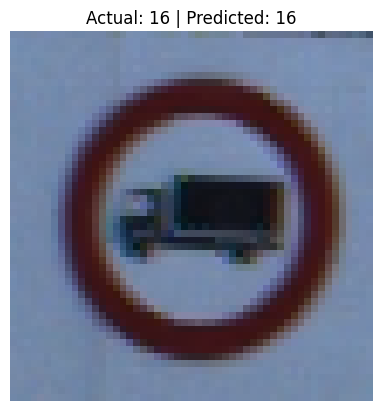

In [18]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

print("DATASET_ROOT:", DATASET_ROOT)

image_path = Path(DATASET_ROOT) / test_df.iloc[0]["Path"]
sign_rgb = np.array(Image.open(image_path).convert("RGB"))
predicted_id, confidence = classify_sign(sign_rgb)
actual_id = int(test_df.iloc[0]["ClassId"])

print("Actual class ID:", actual_id)
print("Predicted class ID:", predicted_id)
print("Confidence:", f"{confidence:.2%}")
print("Correct prediction:", predicted_id == actual_id)

plt.imshow(sign_rgb)
plt.title(f"Actual: {actual_id} | Predicted: {predicted_id}")
plt.axis("off")
plt.show()

## Custom CNN — Final Results Summary

The German Traffic Sign Recognition Benchmark (GTSRB) has 43 traffic sign categories. A Custom Convolutional Neural Network (CNN) has been developed for traffic sign classification.

We trained the model using TensorFlow/Keras with Adam optimizer and learning rate of .001. Validation performance was monitored and the best model saved using early stopping and model checkpointing.

### Model Performance

- **Test Accuracy:** 93.60%
- **Test Loss:** 0.3466
- **Test Images:** 12,630
- **Correct Predictions:** 11,822
- **Incorrect Predictions:** 808

The results indicate that the Custom CNN successfully learned to classify the traffic signs with 93.60% accuracy of the test dataset. However, the performance differences across different traffic sign categories are shown in the classification report. The trained CNN serves as the baseline model for comparison with the YOLO-based approach.